# 7 · Gap ledger: what is in the model, at what fidelity, and what is missing

A virtual cell is only useful if its limits are explicit. This notebook is generated from the model itself.

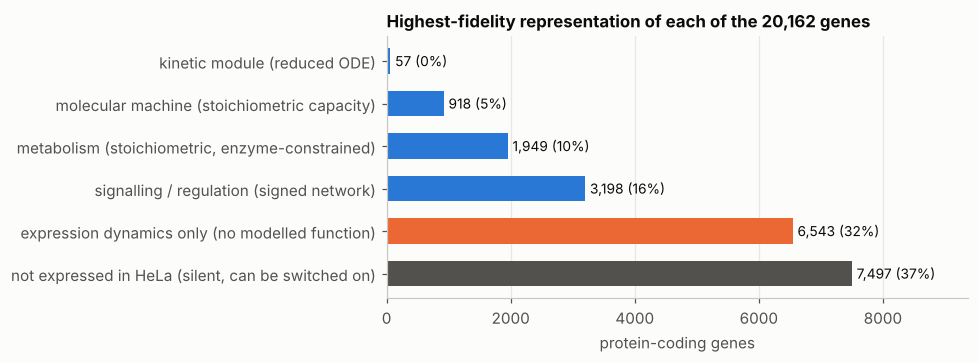

expressed genes: 12,665; with a modelled function: 6,122 (48%); expression dynamics only: 6,543 (52%)


In [1]:
import sys, pathlib; sys.path.insert(0, str(pathlib.Path.cwd().parent))
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from humancell import data, plotting as P; P.style()
from humancell.machinery import MACHINES
from humancell.cell import DRUGS

g = data.build_gene_table("HeLa")
mf = pd.read_csv("../results/modelled_function.csv", index_col=0)
tier = np.select(
    [~mf.expressed, mf.kinetic_module, mf.machine, mf.metabolism, mf.signalling | mf.transcription_factor],
    ["not expressed in HeLa (silent, can be switched on)", "kinetic module (reduced ODE)", "molecular machine (stoichiometric capacity)",
     "metabolism (stoichiometric, enzyme-constrained)", "signalling / regulation (signed network)"],
    default="expression dynamics only (no modelled function)")
counts = pd.Series(tier).value_counts()
order = ["kinetic module (reduced ODE)", "molecular machine (stoichiometric capacity)", "metabolism (stoichiometric, enzyme-constrained)",
         "signalling / regulation (signed network)", "expression dynamics only (no modelled function)", "not expressed in HeLa (silent, can be switched on)"]
counts = counts.reindex(order)
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.barh(counts.index[::-1], counts.values[::-1], color=[P.MUTED, P.SERIES[1], P.SERIES[0], P.SERIES[0], P.SERIES[0], P.SERIES[0]], height=0.6)
for y, v in enumerate(counts.values[::-1]): ax.text(v + 80, y, f"{v:,} ({v / len(mf):.0%})", va="center", fontsize=9)
ax.set_xlim(0, counts.max() * 1.25); ax.grid(axis="y", visible=False); ax.set_xlabel("protein-coding genes")
ax.set_title("Highest-fidelity representation of each of the 20,162 genes")
plt.tight_layout(); plt.show()
expressed = int(mf.expressed.sum()); fun = int((mf.expressed & mf.any_function).sum())
print(f"expressed genes: {expressed:,}; with a modelled function: {fun:,} ({fun / expressed:.0%}); expression dynamics only: {expressed - fun:,} ({1 - fun / expressed:.0%})")

**About half of the expressed genes are simulated only as molecules** (made, degraded, inherited, taking up
mass and ribosome time) with no downstream function. Knocking them out changes nothing in the model. That is
the single largest gap, and for many of these genes it is also a gap in biology: their function is not known
in machine-readable form.

## Processes

In [2]:
P_ = [
 ("Transcription, mRNA decay", "all genes, stochastic", "one rate per gene; no bursting kinetics, promoters, chromatin states, splicing isoforms, miRNA"),
 ("Translation, protein turnover", "all genes, stochastic", "one rate per gene; no codon-level elongation, no uORF/IRES control (ATF4, CHOP), no co-translational folding; 2/3 of half-lives are defaults"),
 ("Molecular machines", f"{len(MACHINES)} curated machines, ~930 genes", "capacity = scarcest subunit with a reserve; no assembly kinetics; composition hand-curated"),
 ("Metabolism", "Human-GEM, 12.7k reactions, 8 compartments", "steady-state fluxes; no metabolite concentrations or allostery; apparent kcat inferred; FBA too permissive (glucose-free growth, methotrexate)"),
 ("Signalling", "5.1k proteins, 14.5k signed edges", "logic-level; uniform weights except a 208-edge backbone; no receptor trafficking, no spatial gradients"),
 ("Gene regulation", "1.1k TFs, 43k TF→gene edges", "log-linear regulon model; fold changes under-estimated; no enhancers, chromatin, 3-D genome"),
 ("Energy / nutrient sensing, ISR, UPR", "reduced ODEs", "phenomenological thresholds; AMPK, mTORC1, GCN2, PERK represented by one variable each"),
 ("Hypoxia, redox", "reduced ODEs", "HIF programme weak; ROS a single lumped variable"),
 ("DNA damage, repair, p53", "DSB count + 3-variable p53–MDM2 loop", "only double-strand breaks; no base/nucleotide excision, mismatch repair, mutations"),
 ("Cell cycle", "checkpoint-gated hybrid automaton", "phase time constants set; no explicit Cdk ODE network; no origin-level replication"),
 ("Apoptosis / necrosis", "bistable caspase switch; energy and osmotic death", "no ferroptosis, necroptosis, pyroptosis, senescence programme"),
 ("Ions, membrane potential, Ca²⁺", "pump-leak + two-pool Ca²⁺", "generic permeabilities; no action potentials, no channel gating, no pH"),
 ("Organelles", "compartment assignment; import machinery limits synthesis", "no organelle biogenesis, fission/fusion, mitophagy, lipid trafficking; no geometry"),
 ("Space", "none (well-mixed compartments)", "no diffusion, no cytoskeleton mechanics, no polarity, no migration"),
 ("Non-coding RNA", "rRNA/tRNA synthesis via Pol I/III machine capacity", "no individual tRNAs, snoRNAs, lncRNAs, miRNAs"),
 ("Post-translational state", "implicit in signalling activity", "no explicit phospho-sites, ubiquitin chains, glycoforms, complexes as molecules"),
 ("Epigenome, genome", "gene dosage implicit", "no chromatin marks, methylation, copy-number, mutations, chromosome segregation errors"),
 ("Multicellular context", "medium shared by a culture", "no cell–cell contact, paracrine loops, tissue mechanics"),
]
pd.set_option("display.max_colwidth", 200)
pd.DataFrame(P_, columns=["process", "in the model", "not in the model"]).set_index("process")

,in the model,not in the model
process,,
"Transcription, mRNA decay","all genes, stochastic","one rate per gene; no bursting kinetics, promoters, chromatin states, splicing isoforms, miRNA"
"Translation, protein turnover","all genes, stochastic","one rate per gene; no codon-level elongation, no uORF/IRES control (ATF4, CHOP), no co-translational folding; 2/3 of half-lives are defaults"
Molecular machines,"37 curated machines, ~930 genes",capacity = scarcest subunit with a reserve; no assembly kinetics; composition hand-curated
Metabolism,"Human-GEM, 12.7k reactions, 8 compartments","steady-state fluxes; no metabolite concentrations or allostery; apparent kcat inferred; FBA too permissive (glucose-free growth, methotrexate)"
Signalling,"5.1k proteins, 14.5k signed edges","logic-level; uniform weights except a 208-edge backbone; no receptor trafficking, no spatial gradients"
Gene regulation,"1.1k TFs, 43k TF→gene edges","log-linear regulon model; fold changes under-estimated; no enhancers, chromatin, 3-D genome"
"Energy / nutrient sensing, ISR, UPR",reduced ODEs,"phenomenological thresholds; AMPK, mTORC1, GCN2, PERK represented by one variable each"
"Hypoxia, redox",reduced ODEs,HIF programme weak; ROS a single lumped variable
"DNA damage, repair, p53",DSB count + 3-variable p53–MDM2 loop,"only double-strand breaks; no base/nucleotide excision, mismatch repair, mutations"


## Parameters: measured, inferred, set

In [3]:
e = g[g.expressed]
def frac(col, pat): return f"{e[col].str.contains(pat).mean():.0%}"
par = pd.DataFrame([
 ("mRNA abundance (12.7k)", "measured (HeLa RNA-seq)", frac("mrna_src", "^HPA RNA-seq$"), "imputed from proteome / raised to translation bound"),
 ("protein abundance (12.7k)", "measured (HeLa proteome)", frac("protein_src", "PaxDB HeLa"), "pan-tissue proteome or mRNA regression"),
 ("protein half-life", "measured (mouse orthologue) or curated", frac("t_half_prot_src", "Schwan|literature"), "median 46 h"),
 ("mRNA half-life", "measured (mouse orthologue) or curated", frac("t_half_mrna_src", "Schwan|literature"), "median 9 h"),
 ("transcription / translation rates", "derived", "100%", "from abundance, half-life and growth rate (steady state)"),
 ("metabolic stoichiometry", "curated (Human-GEM)", "100%", "—"),
 ("enzyme capacities", "inferred", "0% measured", "reference flux ÷ 0.5; default kcat 10/s for idle reactions"),
 ("exchange fluxes, growth rate (reference)", "measured ranges (typical cancer line)", "—", "pinned, not predicted"),
 ("signalling topology and signs", "curated (OmniPath) + 208 backbone edges", "100%", "—"),
 ("signalling and regulatory strengths", "set by stability rule", "0% measured", "literature-support weights, global gain from eigenvalue"),
 ("module constants (~60)", "set from textbook time scales", "0% fitted to HeLa", "p53/MDM2 half-lives, repair rate, phase lengths, thresholds"),
], columns=["parameter class", "status", "share measured", "fallback / rule"]).set_index("parameter class")
par

,status,share measured,fallback / rule
parameter class,,,
mRNA abundance (12.7k),measured (HeLa RNA-seq),79%,imputed from proteome / raised to translation bound
protein abundance (12.7k),measured (HeLa proteome),74%,pan-tissue proteome or mRNA regression
protein half-life,measured (mouse orthologue) or curated,33%,median 46 h
mRNA half-life,measured (mouse orthologue) or curated,31%,median 9 h
transcription / translation rates,derived,100%,"from abundance, half-life and growth rate (steady state)"
metabolic stoichiometry,curated (Human-GEM),100%,—
enzyme capacities,inferred,0% measured,reference flux ÷ 0.5; default kcat 10/s for idle reactions
"exchange fluxes, growth rate (reference)",measured ranges (typical cancer line),—,"pinned, not predicted"
signalling topology and signs,curated (OmniPath) + 208 backbone edges,100%,—


## What it would take to close the gaps

1. **Learn regulatory and signalling weights from perturbation atlases** (Perturb-seq, drug–transcriptome
   data) on the fixed topology. This is the hybrid mechanistic–ML step, and the model's interfaces
   (`Signaling.W`, `Signaling.R`) are the two sparse matrices to fit.
2. **Per-cell-line dependency data** (DepMap) to score cell-line-specific predictions, and more cell lines
   (the data layer already builds HepG2, K-562, U2OS, A549, MCF-7, HEK293, RPE-1 tables from HPA).
3. **Measured human half-lives and absolute metabolite concentrations** to replace the median fallbacks and
   to move metabolism from flux balance to kinetics where data allow.
4. **Functions for the function-less half** of the expressed genome: complexes from CORUM/hu.MAP as generic
   machines, Reactome pathways as additional modules.
5. **Space**: organelle volumes, diffusion-limited steps, and a spatial solver for the processes where
   geometry matters (mitosis, signalling gradients, secretion).
6. **Explicit molecular states**: phosphorylation sites, complexes as molecules, chromatin.

None of these is blocked by the architecture: each is a new process reading and writing the same shared state.